# TN3K — Tiroid Nodülü Segmentasyonu | Veri Denetimi ve EDA

**Ders:** Tıp ve Biyolojide Bilgisayar Uygulamaları  
**Aşama 1 — 11 Kasım 2026:** Veri seti temini, veri kalite kontrolü, keşifsel veri analizi, ön işleme hazırlığı.

**Görev:** Ultrason görüntülerindeki tiroid nodüllerinin piksel düzeyinde segmentasyonu (ikili maske).  
**Kaynak:** Kaggle `tjahan/tn3k-thyroid-nodule-region-segmentation-dataset`.

https://pubmed.ncbi.nlm.nih.gov/36812810/



TN3K, tiroid ultrason görüntülerinde bulunan nodüllerin segmentasyonunu amaçlayan bir veri seti.

Projede ultrason görüntüsünü modele veriyoruz. Modelden görüntü içerisindeki nodülün bulunduğu bölgeyi piksel düzeyinde belirlemesini istiyoruz.

Bu bir sınıflandırma problemi değil.

Örneğin model yalnızca "nodül var" demeyecek. Nodülün görüntüde kapladığı bölgeyi gösteren bir maske oluşturacak.
### Projenin amacı
Temel amaç: Tiroid ultrason görüntülerindeki nodül bölgelerini otomatik olarak tespit edip sınırlarını belirlemek.

Daha teknik olarak:
- Ultrason görüntülerinden anlamlı özellikleri öğrenmek.
- Nodül ve arka plan piksellerini birbirinden ayırmak.
- Uzman anotasyonlarına benzer segmentasyon maskeleri üretmek.
- Farklı büyüklüklerdeki nodüllerde model performansını değerlendirmek.
Burada hedef doğrudan iyi huylu/kötü huylu teşhisi koymak değil, nodülün konumunu ve sınırlarını belirlemek.

## 1. Ortam ve kütüphaneler

Colab'ın standart Python paketleri yeterlidir. Gerekirse eksik paketleri ayrıca kurarız. GPU, EDA için gerekli değildir.

In [ ]:
from pathlib import Path
from collections import Counter
import os, sys, platform, random
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.system())
print("Çalışma dizini:", Path.cwd())

Python: 3.13.18
Platform: Linux
Çalışma dizini: /content


## 2. Veri setine erişim — birlikte tamamlanacak

`ROOT` doğrudan `trainval-image`, `trainval-mask`, `test-image`, `test-mask` klasörlerini içeren dizin olmalı. Şimdilik bağlantıyı kurmuyoruz. Colab'a geçince Kaggle'dan indirme veya Drive bağlantısı yöntemini birlikte seçeceğiz.

In [ ]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

ROOT = project_root / "data" / "tn3k"
SUBDIRS = ["trainval-image", "trainval-mask", "test-image", "test-mask"]

missing = [name for name in SUBDIRS if not (ROOT / name).is_dir()]
if missing:
    raise FileNotFoundError(
        f"TN3K klasörleri bulunamadı: {', '.join(missing)}\n"
        f"Beklenen veri dizini: {ROOT}\n"
        "Veri setini README'deki dizin yapısına göre yerleştirin."
    )

print("Veri dizini:", ROOT)

100%|██████████| 176M/176M [00:01<00:00, 154MB/s]

Extracting files...


İndirilen veri setinin konumu: /root/.cache/kagglehub/datasets/tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2

Veri setindeki klasörler:
test-image
test-mask
trainval-image
trainval-mask
Ayarlanan veri dizini: /root/.cache/kagglehub/datasets/tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2
Mevcut mu? True
Eksik alt klasörler: []


## 3. Veri bağlantısı doğrulama



In [ ]:
assert ROOT.is_dir(), f'Veri klasörü bulunamadı: {ROOT}. Önce 2. bölümdeki ROOT yolunu düzeltin.'
missing = [d for d in SUBDIRS if not (ROOT / d).is_dir()]
assert not missing, f'Eksik klasörler: {missing}'

dirs = {d: ROOT / d for d in SUBDIRS}
files = {d: sorted((ROOT / d).glob('*.jpg')) for d in SUBDIRS}
summary = pd.DataFrame([
    {'Klasör': d, 'JPG sayısı': len(files[d]),
     'Boyut (MiB)': round(sum(p.stat().st_size for p in files[d]) / 1024**2, 2)}
    for d in SUBDIRS
])
display(summary)
print('Toplam JPG:', sum(len(v) for v in files.values()))
print('Toplam boyut (MiB):', round(sum(p.stat().st_size for v in files.values() for p in v) / 1024**2, 2))

,Klasör,JPG sayısı,Boyut (MiB)
0,trainval-image,2879,125.64
1,trainval-mask,2879,16.64
2,test-image,614,35.36
3,test-mask,614,4.67


Toplam JPG: 6986
Toplam boyut (MiB): 182.31


## 4. Dosya bütünlüğü ve eşleşme kontrolü

Görüntü ve maskelerin birebir eşleşmesi gerekir. **Hem trainval hem test** kümesi kontrol edilir. Test görüntüleri burada yalnızca denetlenir; model ayarlamak için kullanılmaz.

In [ ]:
pair_paths = {}
for split in ['trainval', 'test']:
    images = {p.name: p for p in files[f'{split}-image']}
    masks = {p.name: p for p in files[f'{split}-mask']}
    common = sorted(images.keys() & masks.keys())
    only_image = sorted(images.keys() - masks.keys())
    only_mask = sorted(masks.keys() - images.keys())
    pair_paths[split] = [(images[n], masks[n]) for n in common]
    print(f'{split}: image={len(images)}, mask={len(masks)}, eşleşen={len(common)}, '
          f'maskesiz görüntü={len(only_image)}, görüntüsüz maske={len(only_mask)}')
    if only_image: print('  İlk maskesiz görüntüler:', only_image[:10])
    if only_mask: print('  İlk görüntüsüz maskeler:', only_mask[:10])

assert pair_paths['trainval'], 'Trainval için eşleşen görüntü/maske bulunamadı.'

trainval: image=2879, mask=2879, eşleşen=2879, maskesiz görüntü=0, görüntüsüz maske=0
test: image=614, mask=614, eşleşen=614, maskesiz görüntü=0, görüntüsüz maske=0


**3.493**
*Görüntü–maske çifti*


**0**
*Bozuk/eşleşmeyen çift*

## 5. Tüm görüntülerin açılabilirliği, boyutu ve renk modu

JPEG dosyalarının okunabilirliği, görüntü-mask boyut uyumu ve renk kanalı incelenir. Bu işlem tüm dosyalar üzerinde birkaç dakika sürebilir.

In [ ]:
records = []
errors = []
for split, pairs in pair_paths.items():
    for img_path, mask_path in pairs:
        try:
            with Image.open(img_path) as im:
                im.verify()
            with Image.open(mask_path) as ma:
                ma.verify()
            with Image.open(img_path) as im, Image.open(mask_path) as ma:
                w, h = im.size
                mw, mh = ma.size
                records.append({'split': split, 'filename': img_path.name,
                                'width': w, 'height': h, 'aspect_ratio': w/h,
                                'image_mode': im.mode, 'mask_mode': ma.mode,
                                'same_size': (w, h) == (mw, mh),
                                'image_path': str(img_path), 'mask_path': str(mask_path)})
        except (OSError, ValueError, UnidentifiedImageError) as exc:
            errors.append((split, img_path.name, str(exc)))

df = pd.DataFrame(records)
print('Okunabilen çift:', len(df), '| Hatalı çift:', len(errors))
print('Boyutu uyuşmayan çift:', int((~df['same_size']).sum()) if len(df) else 0)
print('Görüntü modları:', df['image_mode'].value_counts().to_dict() if len(df) else {})
print('Maske modları:', df['mask_mode'].value_counts().to_dict() if len(df) else {})
if errors: display(pd.DataFrame(errors, columns=['split', 'dosya', 'hata']).head(20))
if len(df): display(df.groupby('split')[['width','height','aspect_ratio']].agg(['min','median','max']).round(2))
assert len(df) > 0, 'İncelenebilen görüntü çifti yok.'

Okunabilen çift: 3493 | Hatalı çift: 0
Boyutu uyuşmayan çift: 0
Görüntü modları: {'L': 3493}
Maske modları: {'L': 3493}


width              height             aspect_ratio             
           min median   max    min median  max          min median   max
split                                                                   
test       255  436.0  1399    261  375.0  772         0.81   1.23  1.98
trainval   184  390.0  1463    174  336.0  826         0.52   1.12  2.04

## 6. Görüntü boyutları — keşifsel analiz

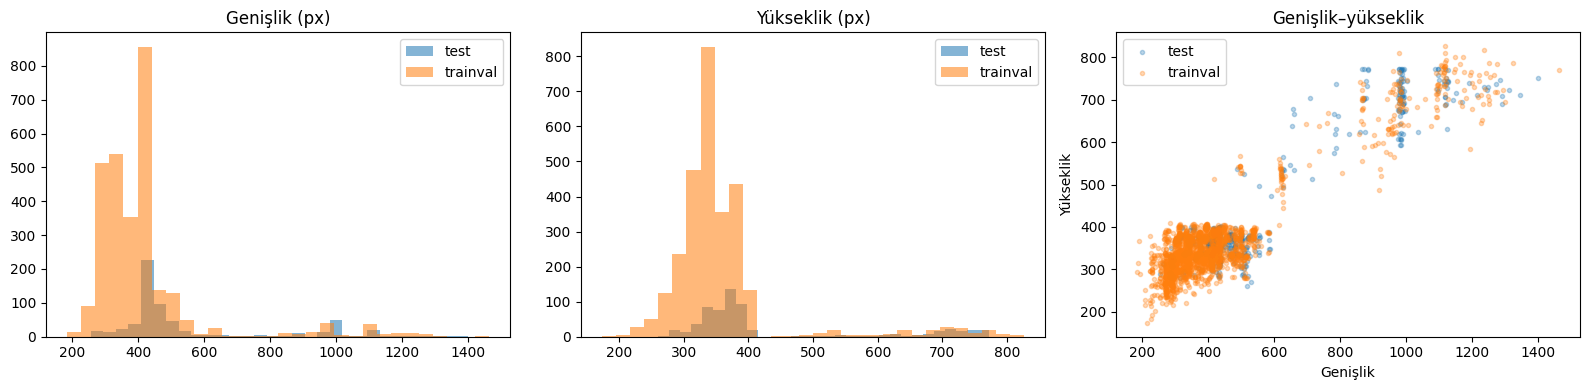

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for split, part in df.groupby('split'):
    axes[0].hist(part['width'], bins=30, alpha=0.55, label=split)
    axes[1].hist(part['height'], bins=30, alpha=0.55, label=split)
    axes[2].scatter(part['width'], part['height'], s=9, alpha=0.3, label=split)
for ax, label in zip(axes, ['Genişlik (px)', 'Yükseklik (px)', 'Genişlik–yükseklik']):
    ax.set_title(label)
    ax.legend()
axes[2].set_xlabel('Genişlik'); axes[2].set_ylabel('Yükseklik')
plt.tight_layout(); plt.show()

Eğitim/doğrulama kümesindeki görüntülerin medyan genişliği 390 piksel, medyan yüksekliği 336 pikseldir.

Test kümesindeki görüntülerin medyan genişliği 436 piksel, medyan yüksekliği 375 pikseldir.

Görüntülerin büyük bölümü yaklaşık 250–500 piksel genişlik aralığında yoğunlaşmaktadır.

Bazı görüntülerin genişliği 1.400 pikselin üzerine çıkmaktadır.

Görüntülerin en-boy oranları da farklılık göstermektedir.

Histogramlar incelendiğinde görüntülerin tek bir çözünürlükte bulunmadığı ve farklı boyut gruplarının oluştuğu gözlemlenmiştir.

Saçılım grafiği ise görüntü genişliği ile yüksekliği arasında genel olarak pozitif bir ilişki bulunduğunu göstermektedir.

Eğitim/doğrulama ve test kümelerinin çözünürlük dağılımları genel olarak benzer bölgelerde yoğunlaşmakla birlikte, bu gözlem iki kümenin istatistiksel olarak aynı dağılıma sahip olduğunu kanıtlamamaktadır.

Modelleme açısından değerlendirme:

U-Net gibi segmentasyon modellerinde görüntülerin ortak bir giriş boyutuna dönüştürülmesi gerekmektedir.

Ancak farklı en-boy oranlarına sahip görüntülerin doğrudan kare boyuta dönüştürülmesi anatomik yapıların geometrik özelliklerini değiştirebilir.

Bu nedenle sonraki aşamada doğrudan yeniden boyutlandırma (resize) ve en-boy oranını koruyarak padding uygulama yöntemlerinin karşılaştırılması planlanmaktadır.

Ayrıca farklı giriş çözünürlüklerinin özellikle küçük nodüllerin segmentasyon başarısına etkisi değerlendirilecektir.

## 7. Görüntü, orijinal maske ve maske bindirmesi

JPEG maskelerinde sıkıştırmadan kaynaklanan ara gri tonları bulunabilir. `>=128` **geçici** bir ikilileştirme eşik değeridir; görsel olarak kontrol edilir.

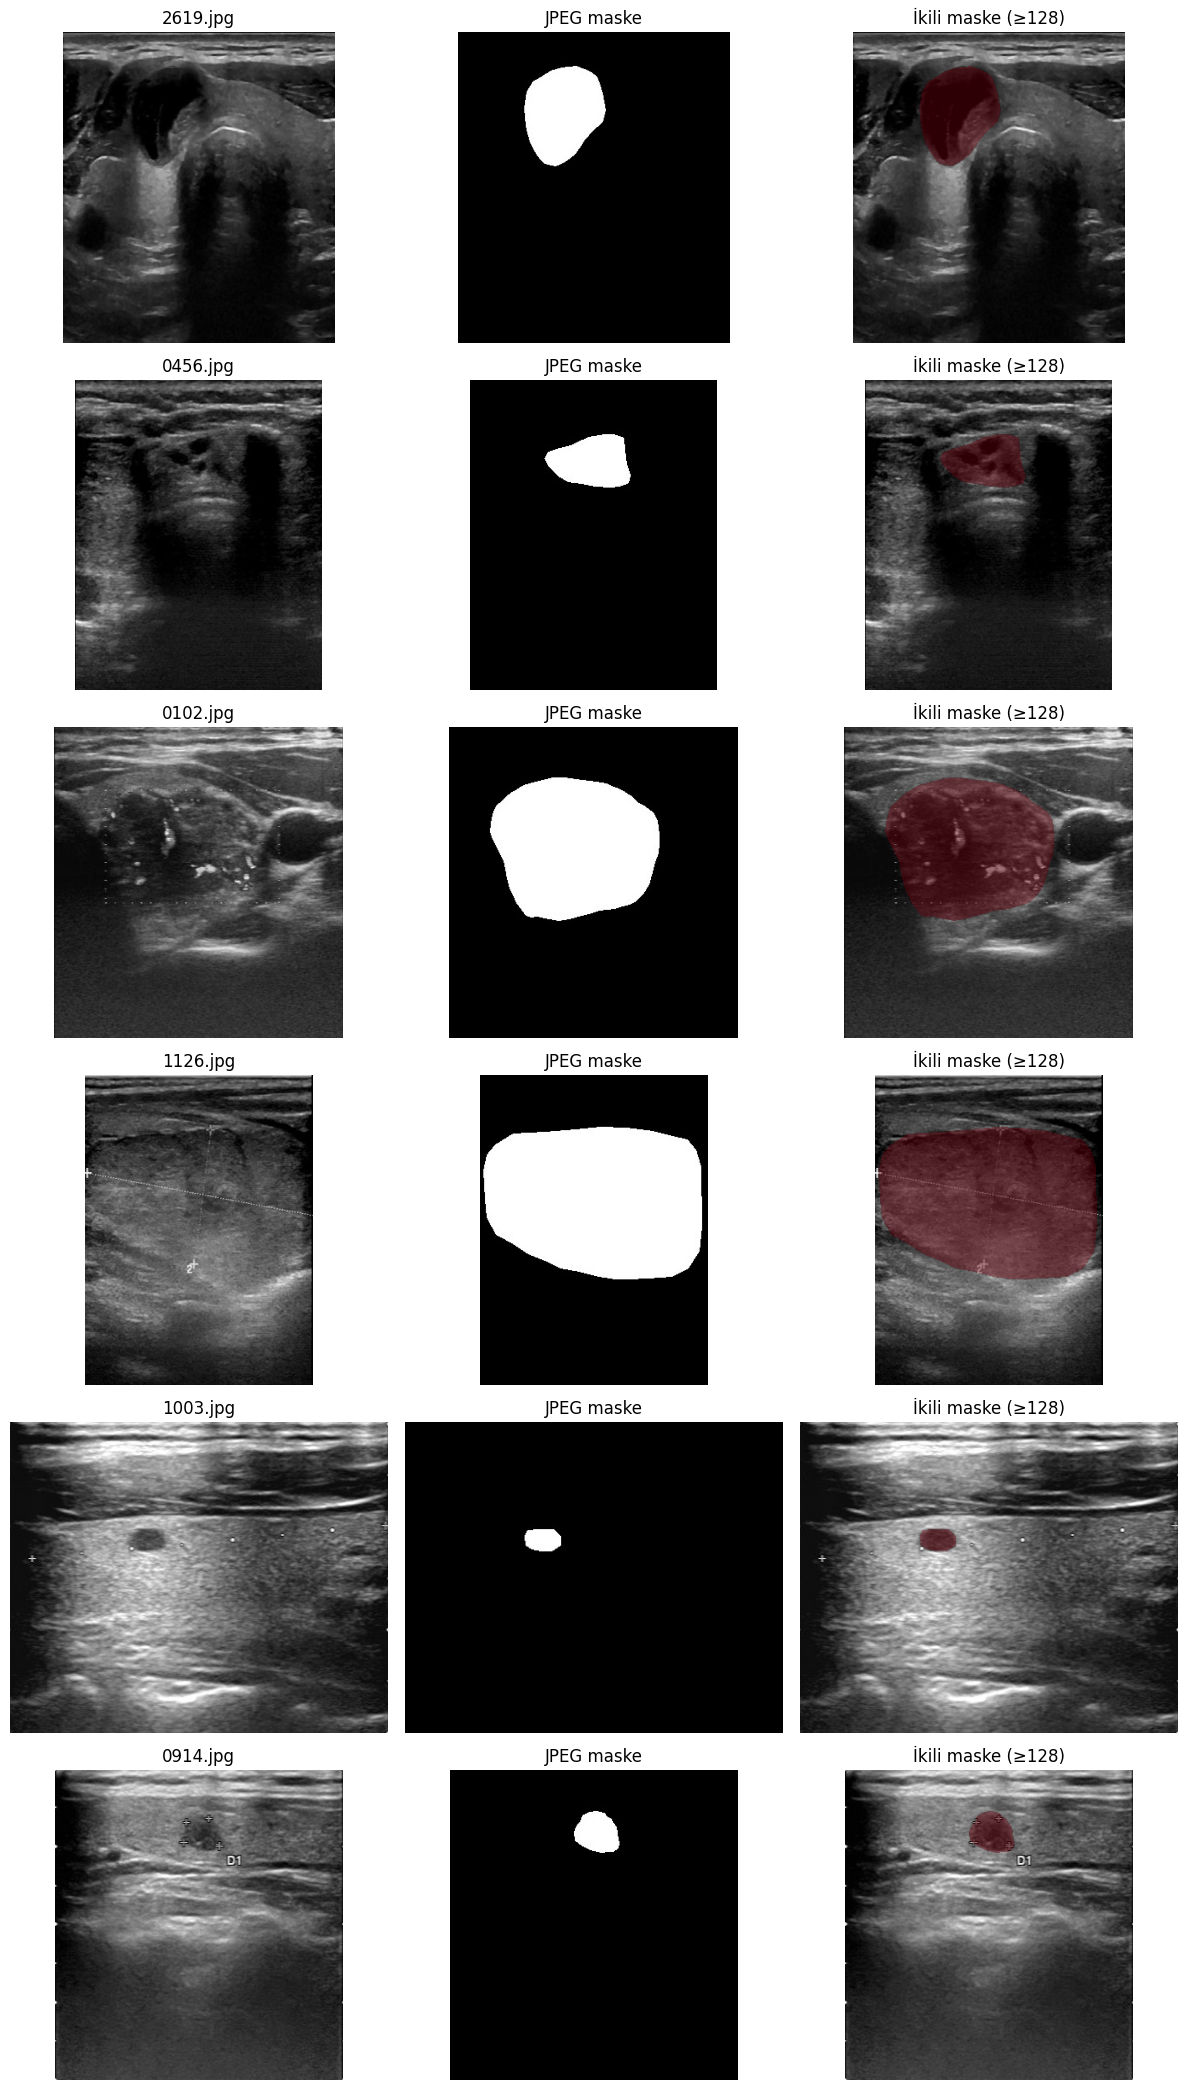

In [ ]:
def show_examples(pairs, n=6, seed=SEED, threshold=128):
    chosen = random.Random(seed).sample(pairs, min(n, len(pairs)))
    fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 3.5*len(chosen)), squeeze=False)
    for axrow, (ip, mp) in zip(axes, chosen):
        with Image.open(ip) as im, Image.open(mp) as ma:
            image = np.asarray(im.convert('L'))
            mask = np.asarray(ma.convert('L'))
        binary = mask >= threshold
        axrow[0].imshow(image, cmap='gray'); axrow[0].set_title(ip.name)
        axrow[1].imshow(mask, cmap='gray', vmin=0, vmax=255); axrow[1].set_title('JPEG maske')
        axrow[2].imshow(image, cmap='gray')
        axrow[2].imshow(np.ma.masked_where(~binary, binary), cmap='Reds', alpha=.45, vmin=0, vmax=1)
        axrow[2].set_title(f'İkili maske (≥{threshold})')
        for ax in axrow: ax.axis('off')
    plt.tight_layout(); plt.show()

show_examples(pair_paths['trainval'])

Her örnek için üç farklı görselleştirme oluşturulmuştur:

Orijinal ultrason görüntüsü: Tiroid dokusunun ve nodülün bulunduğu gri tonlamalı görüntü.

Segmentasyon maskesi: Nodül bölgesinin işaretlendiği anotasyon görüntüsü.

Maske bindirmesi (overlay): Nodül maskesinin orijinal ultrason görüntüsü üzerinde yarı saydam kırmızı renkle gösterilmesi.

Maske bindirmesi sırasında JPEG formatındaki maskeler, 128 eşik değeri kullanılarak ikili formata dönüştürülmüştür.

Görsel analiz bulguları:

İncelenen örneklerde nodül bölgelerinin farklı boyut ve şekillere sahip olduğu gözlemlenmiştir.

Bazı nodüller görüntünün küçük bir bölümünü kaplarken bazıları görüntünün önemli bir alanına yayılmaktadır.

Nodül bölgelerinin görüntü içerisindeki konumları farklılık göstermektedir.

Bazı ultrason görüntülerinde ölçüm işaretleri ve cihaz kaynaklı görsel unsurlar bulunmaktadır.

Görüntüler arasında parlaklık, kontrast ve doku görünümü açısından farklılıklar mevcuttur.

Maske bindirmeleri, seçilen örneklerde segmentasyon anotasyonlarının orijinal görüntüler üzerindeki konumlarının görsel olarak tutarlı olduğunu göstermektedir.

## 8. JPEG maske değerleri ve eşikleme duyarlılığı

Tek bir maskede görülen benzersiz piksel değerleri ve örnek maskelerde farklı eşiklerin oluşturduğu alan oranları karşılaştırılır. Eşik seçimi **test kümesinin performansına göre optimize edilmez**.

In [ ]:
sample_pairs = pair_paths['trainval'][:min(30, len(pair_paths['trainval']))]
rows = []
for ip, mp in sample_pairs:
    with Image.open(mp) as ma: mask = np.asarray(ma.convert('L'))
    rows.append({'file': mp.name, **{f'ratio_{t}': float((mask >= t).mean()*100) for t in [64, 128, 192]}})
threshold_df = pd.DataFrame(rows)
display(threshold_df.head(10).round(3))
print('Eşikler arası en büyük yüzde puan farkı (64–192):',
      round((threshold_df['ratio_64'] - threshold_df['ratio_192']).abs().max(), 3))
with Image.open(sample_pairs[0][1]) as ma: example_mask = np.asarray(ma.convert('L'))
print('İlk maskenin örnek benzersiz piksel değerleri:', np.unique(example_mask)[:30])

,file,ratio_64,ratio_128,ratio_192
0,0000.jpg,10.533,10.533,10.533
1,0001.jpg,11.780,11.780,11.780
2,0002.jpg,13.426,13.426,13.426
3,0003.jpg,7.142,7.142,7.142
4,0004.jpg,1.544,1.544,1.544
5,0005.jpg,2.953,2.953,2.953
6,0006.jpg,1.582,1.582,1.582
7,0007.jpg,13.166,13.166,13.166
8,0008.jpg,5.093,5.093,5.093
9,0009.jpg,8.515,8.515,8.515


Eşikler arası en büyük yüzde puan farkı (64–192): 0.0
İlk maskenin örnek benzersiz piksel değerleri: [  0   1   2   3   4   5   6   7   8   9  10 244 245 246 247 248 249 250
 251 252 253 254 255]


In [ ]:
threshold_differences = []

for _, mask_path in pair_paths["trainval"]:
    with Image.open(mask_path) as ma:
        mask = np.asarray(ma.convert("L"))

    ratio_64 = (mask >= 64).mean()
    ratio_128 = (mask >= 128).mean()
    ratio_192 = (mask >= 192).mean()

    threshold_differences.append({
        "file": mask_path.name,
        "difference_64_128": abs(ratio_64 - ratio_128) * 100,
        "difference_128_192": abs(ratio_128 - ratio_192) * 100
    })

threshold_check = pd.DataFrame(threshold_differences)

print("İncelenen maske:", len(threshold_check))

print(
    "64–128 arasında farklı sonuç veren maske:",
    (threshold_check["difference_64_128"] > 0).sum()
)

print(
    "128–192 arasında farklı sonuç veren maske:",
    (threshold_check["difference_128_192"] > 0).sum()
)

print(
    "En yüksek yüzde puan fark:",
    threshold_check[
        ["difference_64_128", "difference_128_192"]
    ].max().max()
)

İncelenen maske: 2879
64–128 arasında farklı sonuç veren maske: 0
128–192 arasında farklı sonuç veren maske: 0
En yüksek yüzde puan fark: 0.0


### Maske İkilileştirme ve Eşik Değeri Duyarlılık Analizi

TN3K veri setindeki segmentasyon maskeleri JPEG formatında saklanmaktadır. JPEG formatının kayıplı sıkıştırma özelliği nedeniyle maskelerde yalnızca 0 ve 255 değerleri yerine bu değerlere yakın gri tonları da bulunmaktadır.

Segmentasyon modellerinin eğitimi için maskelerin ikili (binary) formata dönüştürülmesi gerekmektedir. Bu amaçla başlangıçta 128 eşik değeri seçilmiştir.

Seçilen eşik değerinin maskeler üzerindeki etkisini değerlendirmek amacıyla 64, 128 ve 192 olmak üzere üç farklı eşik değeri karşılaştırılmıştır.

**Analiz sonuçları:**

- İncelenen maske sayısı: 2.879
- 64 ve 128 eşikleri arasında farklı sonuç veren maske sayısı: 0
- 128 ve 192 eşikleri arasında farklı sonuç veren maske sayısı: 0
- Maksimum işaretli alan oranı farkı: 0,0 yüzde puan

**Değerlendirme:**

Analiz sonucunda, üç farklı eşik değerinin bütün eğitim/doğrulama maskelerinde aynı ikili segmentasyon sonuçlarını ürettiği belirlenmiştir.

Bu durum, maskelerde arka plan ve nodül bölgelerine ait piksel değerlerinin birbirinden belirgin şekilde ayrıldığını ve incelenen eşik aralığında sınıflandırmayı değiştirecek ara piksel değerlerinin bulunmadığını göstermektedir.

Bu bulgular doğrultusunda, sonraki veri hazırlama aşamalarında maskelerin ikili formata dönüştürülmesi için **128 eşik değerinin kullanılması** uygun görülmüştür.

Bu analiz, eşikleme işleminin tutarlılığını doğrulamakta olup segmentasyon anotasyonlarının klinik doğruluğunu değerlendirmemektedir.

## 9. Trainval maskelerinde nodül alanı analizi

Her maskenin işaretli piksel oranı; medyan, çeyrekler, uç değerler ve boş/tam maske kontrolleri. Ayrılmış **test kümesini EDA kararlarında kullanmıyoruz**.

,foreground_pct
count,2879.000
mean,14.222
std,14.335
min,0.204
1%,0.469
25%,3.335
50%,8.569
75%,21.151
99%,59.974
max,75.884


Boş maske: 0
Tamamen işaretli maske: 0


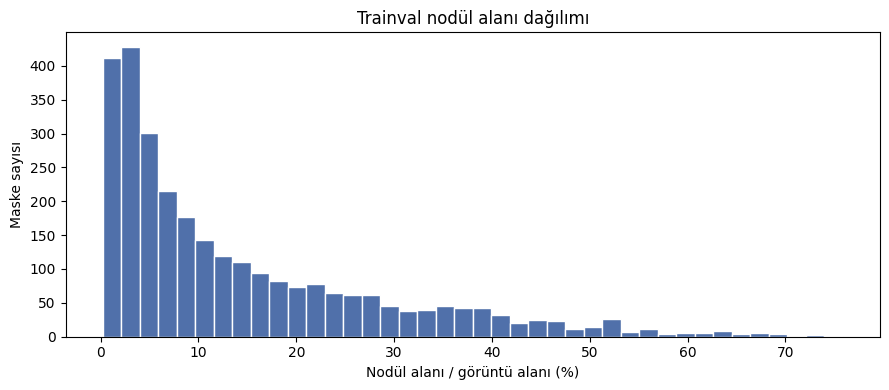

In [ ]:
mask_rows = []
for ip, mp in pair_paths['trainval']:
    try:
        with Image.open(mp) as ma: mask = np.asarray(ma.convert('L'))
        binary = mask >= 128
        mask_rows.append({'file': mp.name, 'foreground_pct': float(binary.mean()*100),
                          'foreground_pixels': int(binary.sum()), 'total_pixels': int(binary.size)})
    except (OSError, UnidentifiedImageError) as exc:
        print('Maske okunamadı:', mp.name, exc)

mask_df = pd.DataFrame(mask_rows)
display(mask_df['foreground_pct'].describe(percentiles=[.01,.25,.5,.75,.99]).to_frame().round(3))
print('Boş maske:', int((mask_df['foreground_pixels']==0).sum()))
print('Tamamen işaretli maske:', int((mask_df['foreground_pixels']==mask_df['total_pixels']).sum()))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(mask_df['foreground_pct'], bins=40, color='#5070aa', edgecolor='white')
ax.set(xlabel='Nodül alanı / görüntü alanı (%)', ylabel='Maske sayısı', title='Trainval nodül alanı dağılımı')
plt.tight_layout(); plt.show()

### Nodül Alan Dağılımının İstatistiksel Değerlendirmesi

TN3K veri setinin eğitim/doğrulama bölümündeki 2.879 segmentasyon maskesi incelenerek nodül bölgelerinin toplam görüntü alanına oranları hesaplanmıştır.

Analiz sonucunda ortalama nodül alanı oranı %14,22, medyan ise %8,57 olarak bulunmuştur. Ortalama değerin medyandan yüksek olması ve histogramın sağa doğru uzanan bir kuyruk göstermesi, nodül alanlarının sağa çarpık bir dağılıma sahip olduğunu ortaya koymaktadır.

Maskelerin %25'inde nodül alanı görüntünün yaklaşık %3,34'ünden daha az veya eşitken, %75'inde bu oran yaklaşık %21,15'in altında veya eşittir. En küçük nodül alanı oranı %0,20, en büyük oran ise %75,88 olarak belirlenmiştir.

Ayrıca veri setinde tamamen boş veya bütünüyle işaretlenmiş maske bulunmamıştır.

**Modelleme açısından değerlendirme:**

- Nodül alanlarının geniş bir aralıkta değişmesi, modelin farklı büyüklüklerdeki hedef bölgeleri öğrenmesini gerektirmektedir.
- Küçük nodül alanlarının yaygın olması, segmentasyon sırasında arka plan piksellerinin baskın olabileceğini göstermektedir.
- Bu nedenle yalnızca piksel doğruluğu yerine Dice ve IoU gibi segmentasyon metriklerinin kullanılması planlanmaktadır.
- Modelin küçük nodüllerdeki başarısının ayrıca incelenmesi önerilmektedir.

Bu bulgular, sonraki aşamada geliştirilecek U-Net tabanlı segmentasyon modelinin eğitim ve değerlendirme stratejisinin belirlenmesine katkı sağlamaktadır.

## 10. Uç örneklerin görsel incelenmesi

Çok küçük ve çok büyük maskeler olası segmentasyon zorluklarını gösterir. Bunların hata olduğu varsayılmaz; görüntülerle birlikte kontrol edilir.

En küçük nodül oranları ['1725.jpg', '2318.jpg', '0267.jpg']


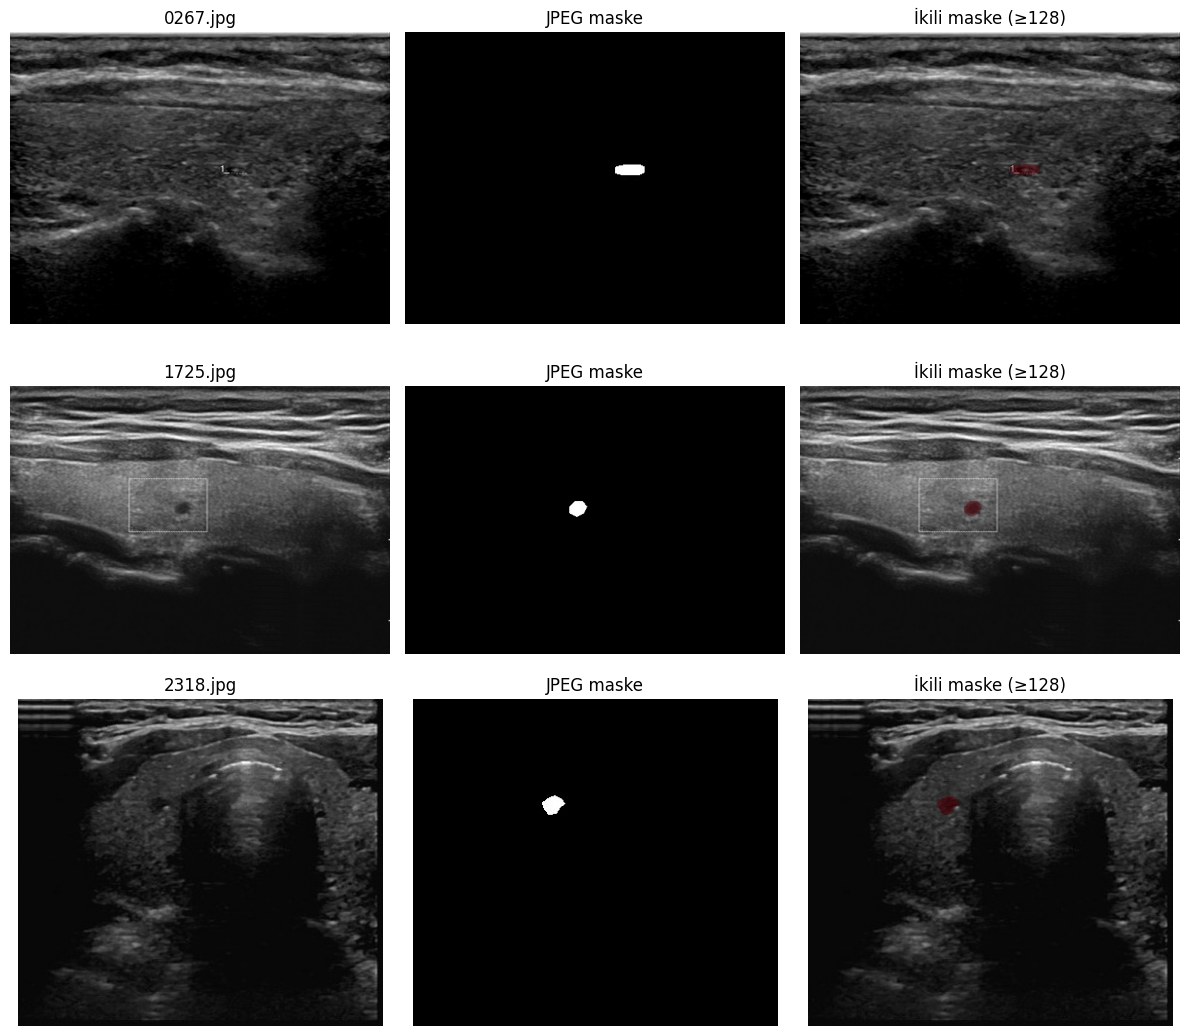

En büyük nodül oranları ['0941.jpg', '0056.jpg', '0606.jpg']


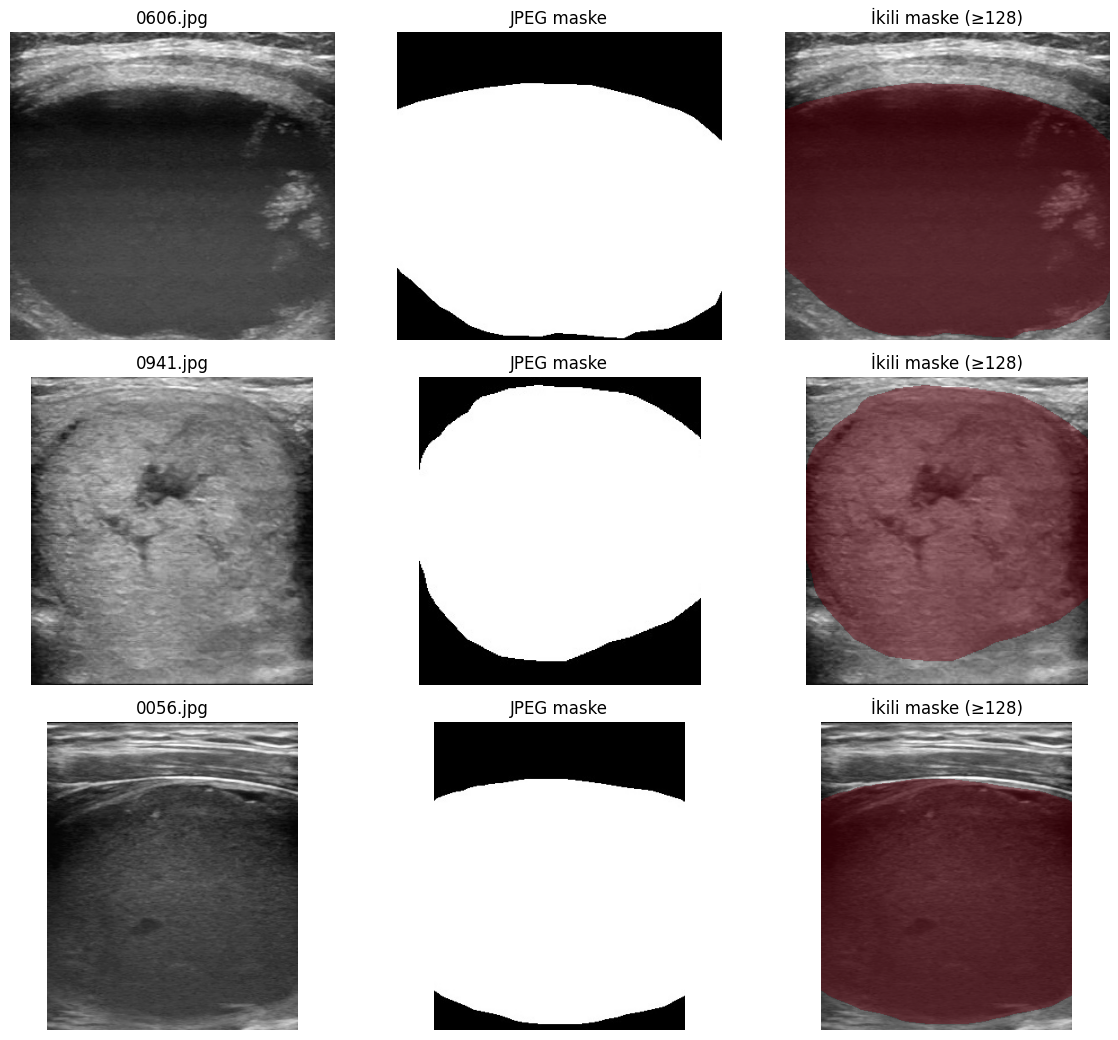

In [ ]:
for label, chosen_names in [
    ('En küçük nodül oranları', mask_df.nsmallest(3, 'foreground_pct')['file'].tolist()),
    ('En büyük nodül oranları', mask_df.nlargest(3, 'foreground_pct')['file'].tolist())
]:
    print(label, chosen_names)
    chosen = [(dirs['trainval-image']/name, dirs['trainval-mask']/name) for name in chosen_names]
    show_examples(chosen, n=len(chosen), seed=SEED)

## 11. Yinelenen dosya adları ve içerik kontrolü

Dosya adlarının farklı klasörlerde aynı olması normaldir. **Aynı görüntü içeriğinin** trainval ve testte bulunması ise veri sızıntısı riski doğurabilir. Aşağıdaki kontrol dosya byte'larının birebir eşitliğini yakalar; yakın kopyaları yakalamaz.

In [ ]:
import hashlib
def digest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

hashes = {}
for split in ['trainval', 'test']:
    hashes[split] = {digest(p): p.name for p in files[f'{split}-image']}
overlap = set(hashes['trainval']) & set(hashes['test'])
print('Trainval–test birebir aynı dosya içeriği:', len(overlap))
if overlap: print('Örnek:', [(hashes['trainval'][h], hashes['test'][h]) for h in list(overlap)[:10]])
print('Not: Yakın kopya ve hasta düzeyinde örtüşme için ayrıca metadata gerekir.')

Trainval–test birebir aynı dosya içeriği: 0
Not: Yakın kopya ve hasta düzeyinde örtüşme için ayrıca metadata gerekir.


### Nodül Alan Dağılımı ve Veri Bütünlüğü Bulguları

TN3K veri setinin eğitim/doğrulama bölümündeki segmentasyon maskeleri incelenerek nodül bölgelerinin görüntü alanına oranları hesaplanmıştır.

Elde edilen histogram, nodül alanlarının sağa çarpık bir dağılım gösterdiğini ortaya koymuştur. Görüntülerin önemli bir bölümünde nodüller toplam piksel alanının küçük bir kısmını kaplarken, bazı örneklerde işaretli alan görüntünün büyük bölümüne ulaşmaktadır.

Bu durum, geliştirilecek segmentasyon modelinin farklı ölçeklerdeki nodülleri başarılı biçimde tespit edebilmesi gerektiğini göstermektedir.

Özellikle küçük nodüllerde sınırlı sayıdaki hatalı pikselin değerlendirme metrikleri üzerindeki etkisi yüksek olabileceğinden, model performansının Dice ve IoU gibi bölgesel örtüşme metrikleriyle değerlendirilmesi planlanmaktadır.

Ayrıca eğitim/doğrulama ve test kümeleri arasındaki birebir dosya tekrarlarını belirlemek amacıyla SHA-256 tabanlı karşılaştırma yapılmıştır.

**Analiz sonucunda iki veri grubu arasında birebir aynı dosya içeriğine rastlanmamıştır.**

Bununla birlikte, bu yöntem farklı sıkıştırılmış görüntüleri veya aynı hastaya ait farklı görüntüleri tespit etmediğinden hasta düzeyinde veri bağımsızlığı henüz doğrulanmamıştır.

Bu bulgular doğrultusunda veri setinin segmentasyon modeli geliştirmek için kullanılabilir olduğu, ancak görüntü ölçeği farklılıklarının ve olası hasta düzeyinde örtüşmelerin sonraki aşamalarda dikkate alınması gerektiği değerlendirilmiştir.

## 12. Ön işleme örneği (model eğitimi yok)

Örnek olarak görüntü `256×256` boyutuna getiriliyor ve `[0,1]` aralığına ölçekleniyor. **Maske için nearest-neighbor** kullanıyoruz ki ikili etiketler interpolasyonla bozulmasın. Bu aşamada dönüştürülmüş veri diske yazılmaz; asıl görüntüler korunur. En-boy oranı bozulması ve 256×256 çözünürlüğün küçük nodüllere etkisi modelleme öncesinde değerlendirilecek.

Görüntü: (256, 256, 1) float32 aralık: (0.0, 0.9372549057006836)
Maske: (256, 256, 1) uint8 değerler: [0 1]


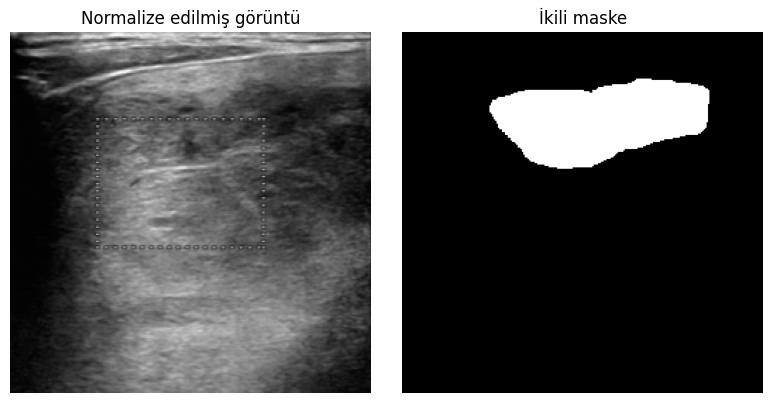

In [ ]:
from PIL import Image as PILImage

def preprocess_pair(image_path, mask_path, size=(256,256), threshold=128):
    with PILImage.open(image_path) as im, PILImage.open(mask_path) as ma:
        assert im.size == ma.size, f'Boyut uyumsuzluğu: {image_path.name}'
        x = np.asarray(im.convert('L').resize(size, resample=PILImage.Resampling.BILINEAR), dtype=np.float32)/255.0
        # JPEG artefaktlarını önce ikilileştir, sonra etiket maskesini NN ile yeniden boyutlandır.
        raw_mask = np.asarray(ma.convert('L'))
        binary_pil = PILImage.fromarray((raw_mask >= threshold).astype(np.uint8))
        y = np.asarray(binary_pil.resize(size, resample=PILImage.Resampling.NEAREST), dtype=np.uint8)
    return x[..., None], y[..., None]

valid_pairs = [(ip, mp) for ip, mp in pair_paths['trainval'] if
               ((df['image_path'] == str(ip)) & df['same_size']).any()]
assert valid_pairs, 'Boyutları eşleşen geçerli trainval çifti bulunamadı.'
x, y = preprocess_pair(*valid_pairs[0])
print('Görüntü:', x.shape, x.dtype, 'aralık:', (float(x.min()), float(x.max())))
print('Maske:', y.shape, y.dtype, 'değerler:', np.unique(y))
fig, ax = plt.subplots(1,2,figsize=(8,4))
ax[0].imshow(x[:,:,0], cmap='gray'); ax[0].set_title('Normalize edilmiş görüntü')
ax[1].imshow(y[:,:,0], cmap='gray', vmin=0, vmax=1); ax[1].set_title('İkili maske')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

Ön işleme örneği: 0000.jpg


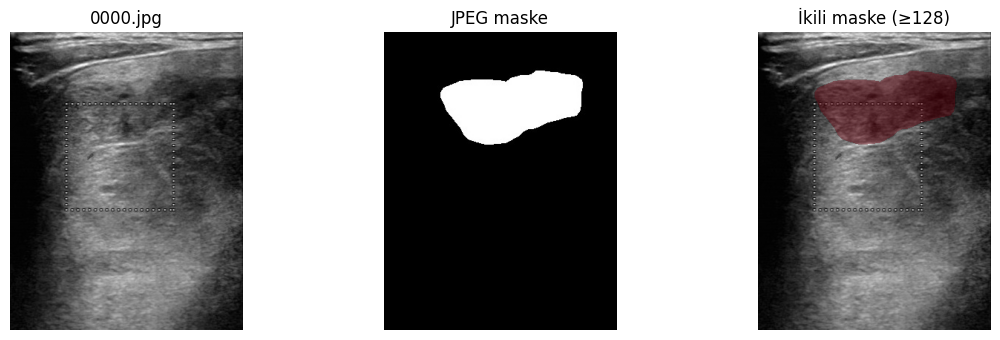

In [ ]:
print("Ön işleme örneği:", valid_pairs[0][0].name)
show_examples([valid_pairs[0]], n=1)

## 13. Eğitim / doğrulama / test stratejisi

- Sağlanan `test-*` klasörleri final, bağımsız değerlendirme için **ayrı kalacak**.
- `trainval-*` içinden (ör. %80/%20) eğitim ve doğrulama grubu ayrılacak.
- Aynı hastaya ait birden fazla görüntü varsa rastgele görüntü ayrımı veri sızıntısına neden olabilir. **Hasta kimliği/metadata olup olmadığı kontrol edilmeden kesin split yapılmamalı.**
- Augmentation yalnızca eğitim grubunda; normalizasyon/dönüşümler görüntü ve maske için eşzamanlı uygulanmalı.
- 26 Kasım hedefi: U-Net başlangıç modeli, Dice/IoU, gerektiğinde precision/recall ve nitel örneklerin karşılaştırılması.



## 14. Veri Seti Ön Analiz Sonuçları

TN3K veri seti üzerinde gerçekleştirilen keşifsel veri analizi ve veri bütünlüğü kontrolleri sonucunda aşağıdaki bulgular elde edilmiştir.

| Kontrol | Sonuç |
|---|---|
| Toplam görüntü sayısı | 3.493 |
| Toplam maske sayısı | 3.493 |
| Toplam dosya sayısı | 6.986 |
| Toplam veri boyutu | 182,31 MiB |
| Eğitim/doğrulama görüntü–maske çifti | 2.879 |
| Test görüntü–maske çifti | 614 |
| Eksik görüntü–maske eşleşmesi | 0 |
| Bozuk veya okunamayan çift | 0 |
| Görüntü–maske boyut uyumsuzluğu | 0 |
| Görüntü renk modu | Grayscale (L) |
| Maske renk modu | Grayscale (L) |
| Görüntü çözünürlükleri | Değişken |
| Maskelerde JPEG sıkıştırma artefaktları | Mevcut |
| Eşikleme yöntemi | Binary threshold (≥128) |
| 64, 128 ve 192 eşikleri arasında farklı sonuç veren trainval maskesi | 0 |
| Boş trainval maskesi | 0 |
| Medyan nodül alanı oranı | %8,57 |
| Minimum nodül alanı oranı | %0,2037 |
| Maksimum nodül alanı oranı | %75,88 |
| Trainval–test arasında birebir aynı dosya içeriği | 0 |

### Genel Değerlendirme

TN3K veri setinin dosya bütünlüğü, görüntü–maske eşleşmeleri, görüntü boyutları ve segmentasyon maskeleri incelenmiştir.

Yapılan kontroller sonucunda veri setindeki bütün görüntü–maske çiftlerinin okunabilir olduğu, dosya eşleşmelerinde eksiklik bulunmadığı ve eşleşen görüntülerle maskelerin boyutlarının uyumlu olduğu belirlenmiştir.

Görüntülerin farklı çözünürlüklere sahip olması nedeniyle model eğitimi öncesinde standart bir giriş boyutu belirlenmesi gerekmektedir. Bu kapsamda 256×256 boyutlandırma ve [0,1] aralığında piksel normalizasyonu örnek olarak uygulanmıştır.

Maskelerde JPEG sıkıştırmasından kaynaklanabilecek ara gri tonları tespit edilmiş ve farklı eşik değerleri karşılaştırılmıştır. Eğitim/doğrulama kümesindeki 2.879 maske üzerinde gerçekleştirilen karşılaştırmada 64, 128 ve 192 eşiklerinin aynı ikili segmentasyon sonuçlarını ürettiği görülmüştür. Bu nedenle 128 eşik değeri ön işleme için uygun bulunmuştur.

Nodül alanlarının dağılımı incelendiğinde, veri setinde küçük nodül bölgelerinin yaygın olduğu ve nodüllerin görüntü içerisinde kapladıkları alanların önemli ölçüde değişkenlik gösterdiği belirlenmiştir.

### Sınırlılıklar ve Gelecek Çalışmalar

- JPEG maskeleri kayıpsız segmentasyon etiketleri olmadığından ikilileştirme gerektirmektedir.
- Görüntülerin farklı çözünürlükleri ve en-boy oranları, uygun yeniden boyutlandırma stratejisinin seçilmesini gerektirmektedir.
- Hasta kimliği bilgileri henüz doğrulanmadığından hasta düzeyinde veri bağımsızlığı kesin olarak gösterilememiştir.
- SHA-256 kontrolü birebir aynı dosya içeriklerini dışlamış olsa da benzer görüntülerin veya aynı hastaya ait farklı görüntülerin bulunmadığını kanıtlamamaktadır.
- Nihai görüntü çözünürlüğü ve model mimarisi henüz belirlenmemiştir.

### Sonraki Aşama

26 Kasım 2026 tarihli ikinci aşamada U-Net tabanlı bir segmentasyon modelinin eğitilmesi, Dice ve IoU metrikleriyle başlangıç performansının değerlendirilmesi ve modelin geliştirilmesine yönelik önerilerin oluşturulması planlanmaktadır.

Projenin geliştirilmesi için neler yapılabilir?


1.Temel U-Net modelini eğitmek

İlk olarak standart U-Net mimarisiyle bir başlangıç performansı elde edebiliriz.
- Giriş: 256×256 grayscale ultrason
- Çıkış: İkili nodül maskesi
- Loss: BCE + Dice Loss
- Metrikler: Dice ve IoU



2.Görüntü boyutlandırma yöntemlerini karşılaştırmak
- Doğrudan resize
- Oranı koruyan resize + padding
- 256×256 ve 512×512 çözünürlük karşılaştırması
Böylece hangi yöntemin nodül sınırlarını daha iyi koruduğunu araştırabiliriz.



3.Veri artırma (augmentation) uygulamak
- Yatay çevirme
- Küçük açılı döndürme
- Parlaklık ve kontrast değişimleri
- Hafif geometrik dönüşümler
Görüntüye uygulanan geometrik dönüşüm, maskeye de aynı şekilde uygulanmalı.



4.Farklı segmentasyon mimarilerini karşılaştırmak
- Standart U-Net
- Attention U-Net
- ResUNet
Böylece yalnızca model eğitmiş değil, mimari karşılaştırması yapmış oluruz.



5.Küçük ve büyük nodüllerin başarısını ayrı incelemek

Nodül alanına göre alt gruplar oluşturarak küçük nodüllerde Dice değerinin düşüp düşmediğini araştırabiliriz.



### Karşılaşabileceğimiz zorluklar
1. Düşük kontrast: Nodül ve çevresindeki doku bazı görüntülerde birbirine çok benzeyebilir.
2. Nodül boyutu farklılıkları: Küçük nodüller yeniden boyutlandırma sırasında ayrıntı kaybedebilir.
3. Belirsiz sınırlar: Ultrason görüntülerinde nodül kenarları net olmayabilir.
4. JPEG maskeleri: Kayıplı sıkıştırma nedeniyle etiketler önce ikili hâle dönüştürülmeli.
5. Veri sızıntısı: Hasta kimliği bilgisi bulunmadan aynı hastadan gelen farklı görüntülerin bağımsızlığı doğrulanamıyor.
6. Genelleme: Model farklı ultrason cihazlarıyla çekilmiş görüntülerde aynı başarıyı göstermeyebilir.

### Değerlendirmem
TN3K'yi seçersek güçlü bir segmentasyon projesi geliştirebiliriz.

En mantıklı araştırma sorumuz şu olur:

“Farklı görüntü çözünürlükleri ve segmentasyon mimarileri, özellikle küçük tiroid nodüllerinin segmentasyon başarısını nasıl etkiler?”